In [3]:
import pandas as pd



In [5]:
# Read the CSV file
file_path = "/Users/bz294/Documents/WhiteZone/Precipitation/eve_data/1738003006_rainfall.csv"  # Replace with the path to your CSV file
data = pd.read_csv(file_path, parse_dates=[0], dayfirst=False)

# Ensure the column names are set correctly
data.columns = ['Date', 'Value']

# Add a column for the "seasonal year" (Dec to March spans two calendar years)
data['SeasonalYear'] = data['Date'].apply(lambda x: x.year if x.month >= 12 else x.year - 1)

# Filter the data for December 1 to March 31
filtered_data = data[
    ((data['Date'].dt.month == 12) & (data['Date'].dt.day >= 1)) |
    ((data['Date'].dt.month >= 1) & (data['Date'].dt.month <= 3))
]

# Group by seasonal year and calculate the average value
result = filtered_data.groupby('SeasonalYear')['Value'].mean()

# Print the result
print(result)

SeasonalYear
2002    0.072333
2003    0.046557
2004    0.025207
2005    0.020909
2006    0.043306
2007    0.030738
2008    0.016116
2009    0.118017
2010    0.042231
2011    0.038934
2012    0.038512
2013    0.040000
2014    0.036529
2015    0.138115
2016    0.072727
2017    0.024215
2018    0.036612
2019    0.041803
2020    0.039091
2021    0.059008
2022    0.066446
2023    0.128607
2024    0.075484
Name: Value, dtype: float64


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_96063/61342924.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(file_path, parse_dates=[0], dayfirst=False)


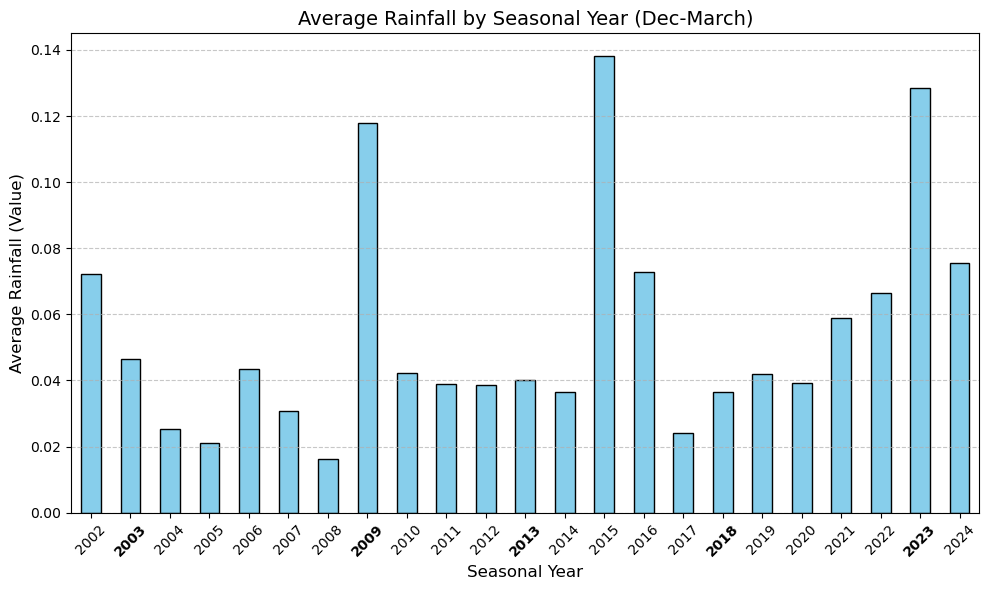

In [8]:
# Plot the result
plt.figure(figsize=(10, 6))
result.plot(kind='bar', color='skyblue', edgecolor='black')

# Customize the plot
plt.title('Average Rainfall by Seasonal Year (Dec-March)', fontsize=14)
plt.xlabel('Seasonal Year', fontsize=12)
plt.ylabel('Average Rainfall (Value)', fontsize=12)

# Set bold font for specific x-axis labels
ax = plt.gca()
for label in ax.get_xticklabels():
    year = int(label.get_text())
    if year in [2003, 2009, 2013, 2018, 2023]:
        label.set_fontweight('bold')
        
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()